# 04 · Customer Lifetime Value (LTV) & unit economics

**Business question:** what is a customer worth, how does that differ by channel, cohort and segment,
and how much can we afford to pay to acquire one?

## Why not `LTV = ARPU × average lifespan`?
That formula assumes a known, constant lifespan and churn rate. Neither exists in non-subscription retail:
customers never "cancel", they just stop buying. It also averages away the heavy skew (a few customers
drive most value) and it can't handle right-censoring (young customers haven't finished buying yet).

## Four views of LTV, from most to least certain
| Type | Definition here | Certainty | Used for |
|---|---|---|---|
| **Historical** | Actual margin a customer has generated to date | Fact, but censored | Value concentration, VIP lists |
| **Fixed-horizon (cohort) LTV** | Avg cumulative margin within *H* days of first order, among customers who have lived ≥ *H* + 30 days | Fact, no censoring | **Channel comparison, LTV:CAC** (primary metric) |
| **Cohort-curve LTV** | Cumulative margin per acquired customer by month since acquisition | Fact, curve shape | Payback period |
| **Predictive LTV** | BG/NBD (purchase count) × Gamma-Gamma (value per order), validated on a holdout year | Estimate | Expected future value of *current* customers |

**Value measure = product gross margin** (net revenue after discounts and returns, minus the cost of goods
kept). Revenue LTV overstates value when discounts and margins differ by channel. The data has **no
fulfilment, payment or RTO logistics costs**, so true contribution is lower. §6 runs an explicitly
assumption-based sensitivity for that.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pathlib import Path

import db
from db import query as q
from run_analysis import run_sql_file
from clv_models import (fit_bgnbd, bgnbd_expected_purchases, bgnbd_p_alive,
                        fit_gamma_gamma, gg_expected_value)
import viz

viz.setup()
A = Path("sql/analysis")
fmt_inr = FuncFormatter(viz.inr)

## 1. Historical LTV is extremely skewed

count     4057.0
mean      1547.0
std       1856.0
min      -1839.0
10%        147.0
25%        482.0
50%       1022.0
75%       1943.0
90%       3428.0
99%       8517.0
max      29547.0


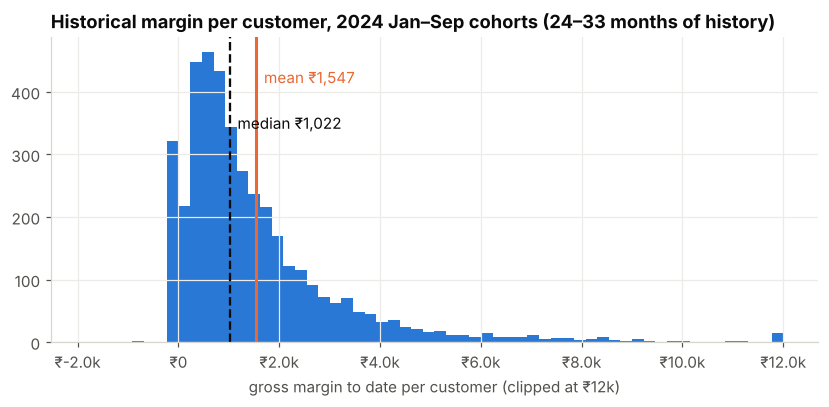

Text(0.0, 1.0, 'Historical margin per customer, 2024 Jan–Sep cohorts (24–33 months of history)')

In [2]:
hist = q("""select margin_to_date, orders_to_date from mart.mart_customer_ltv
            where cohort_month between '2024-01-01' and '2024-09-01'""")
print(hist.margin_to_date.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_string())
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(hist.margin_to_date.clip(upper=12000), bins=60, color=viz.BLUE)
ax.axvline(hist.margin_to_date.mean(), color=viz.ORANGE, lw=2)
ax.axvline(hist.margin_to_date.median(), color=viz.INK, lw=1.5, ls="--")
ax.text(hist.margin_to_date.mean() + 150, ax.get_ylim()[1] * 0.85, f"mean ₹{hist.margin_to_date.mean():,.0f}", color=viz.ORANGE)
ax.text(hist.margin_to_date.median() + 150, ax.get_ylim()[1] * 0.70, f"median ₹{hist.margin_to_date.median():,.0f}", color=viz.INK)
ax.xaxis.set_major_formatter(fmt_inr); ax.set_xlabel("gross margin to date per customer (clipped at ₹12k)")
ax.set_title("Historical margin per customer, 2024 Jan–Sep cohorts (24–33 months of history)")

In [3]:
run_sql_file(A / "09_customer_value_concentration.sql")

,decile,customers,avg_orders,median_margin,total_margin,share_of_margin,cumulative_share,paid_social_share
0,1,406,4.27,4713,2310780,0.368,0.368,0.084
1,2,406,2.18,2748,1135494,0.181,0.549,0.187
2,3,406,1.57,1943,800376,0.128,0.677,0.249
3,4,406,1.40,1508,613043,0.098,0.774,0.278
4,5,406,1.33,1158,473762,0.075,0.850,0.278
5,6,406,1.17,887,359382,0.057,0.907,0.266
6,7,406,1.12,679,275026,0.044,0.951,0.293
7,8,405,1.09,481,194087,0.031,0.982,0.240
8,9,405,1.05,285,110947,0.018,0.999,0.323
9,10,405,1.02,0,4445,0.001,1.000,0.306


- **The top 10% of customers generate ~37% of all margin, and the top 20% generate ~55%.** The bottom decile
  generates roughly nothing (mostly first orders that were fully returned).
- The mean is well above the median, so **report LTV as a mean (it is what pays for CAC) but always show the
  distribution**. A "typical" customer is worth less than the average.
- Paid Social customers are **8% of the top decile but ~29% of the bottom half**.

## 2. Fixed-horizon LTV and LTV:CAC by channel (primary view)

In [4]:
ch = run_sql_file(A / "07_channel_quality_ltv_cac.sql")
ch

,channel,customers_365d_eligible,repeat_rate_365d,first_order_margin,ltv_margin_365d,ltv_revenue_365d,cac,ltv_to_cac_365d,payback_months,max_cac_at_3x
0,Paid Social,2775,0.166,867.0,1069.0,2017.0,1021.0,1.05,4.0,356.0
1,Paid Search,2415,0.312,938.0,1473.0,2708.0,899.0,1.64,0.0,491.0
2,Organic Search,2219,0.321,959.0,1506.0,2801.0,NaN,NaN,NaN,502.0
3,Direct,1167,0.392,962.0,1622.0,3012.0,NaN,NaN,NaN,541.0
4,Affiliate,674,0.254,872.0,1336.0,2548.0,246.0,5.44,0.0,445.0
5,Organic Social,318,0.230,987.0,1349.0,2528.0,NaN,NaN,NaN,450.0
6,Unattributed,308,0.208,929.0,1327.0,2476.0,NaN,NaN,NaN,442.0
7,Referral,263,0.312,901.0,1497.0,2789.0,NaN,NaN,NaN,499.0
8,Email,192,0.380,1008.0,1698.0,3155.0,NaN,NaN,NaN,566.0


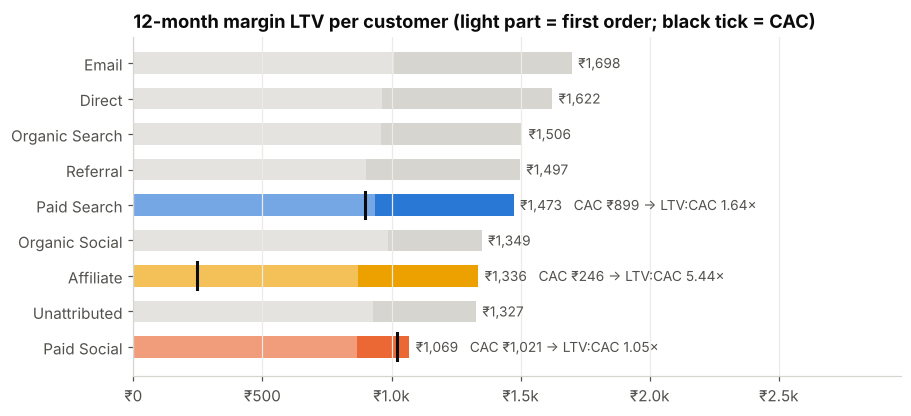

Text(0.0, 1.0, '12-month margin LTV per customer (light part = first order; black tick = CAC)')

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
c2 = ch.sort_values("ltv_margin_365d")
y = np.arange(len(c2))
ax.barh(y, c2.ltv_margin_365d, color=[viz.highlight(c, focus=("Paid Social", "Paid Search", "Affiliate")) for c in c2.channel], height=0.6)
ax.barh(y, c2.first_order_margin, color="white", alpha=0.35, height=0.6)
for i, r in enumerate(c2.itertuples()):
    lab = f"₹{r.ltv_margin_365d:,.0f}"
    if pd.notna(r.cac):
        lab += f"   CAC ₹{r.cac:,.0f} → LTV:CAC {r.ltv_to_cac_365d:.2f}×"
    ax.text(r.ltv_margin_365d + 25, i, lab, va="center", fontsize=9, color=viz.INK_2)
    if pd.notna(r.cac):
        ax.plot([r.cac, r.cac], [i - 0.38, i + 0.38], color=viz.INK, lw=2)
ax.set_yticks(y, c2.channel); ax.grid(axis="y", visible=False)
ax.set_xlim(0, c2.ltv_margin_365d.max() * 1.75); ax.xaxis.set_major_formatter(fmt_inr)
ax.set_title("12-month margin LTV per customer (light part = first order; black tick = CAC)")

**Reading LTV:CAC here.** These ratios use *product* margin over *12 months*, with no fulfilment costs.
A common rule of thumb is ≥ 3× on a lifetime *contribution*-margin basis, so the bar should be at least as
strict here.

- **Paid Social: 12-month margin LTV ₹1,069 vs CAC ₹1,021 → 1.05×.** It barely pays back its acquisition
  cost on product margin alone, and is very likely loss-making after shipping, payment and RTO costs (§6).
- **Paid Search: ₹1,472 vs ₹899 → 1.64×.** Its customers repeat about twice as often (31% vs 17%), so each
  rupee of CAC returns about 55% more 12-month margin (1.64× vs 1.05×).
- **Affiliate: 5.4×**, because commission is paid only on delivered sales. It is cheap and capped by
  availability, not budget. The risk is coupon-site cannibalisation: some of these customers might have
  bought anyway.
- **Unpaid channels** (Organic Search, Direct, Referral) bring the best customers, but their costs (SEO,
  content, brand) aren't in the data. Their CAC is **unknown, not zero**.
- **Email has no acquisition CAC.** Its platform fee serves existing customers. Email-acquired customers
  (newsletter sign-ups who later buy) are few and are the most valuable.

## 3. Cohort-curve LTV and payback

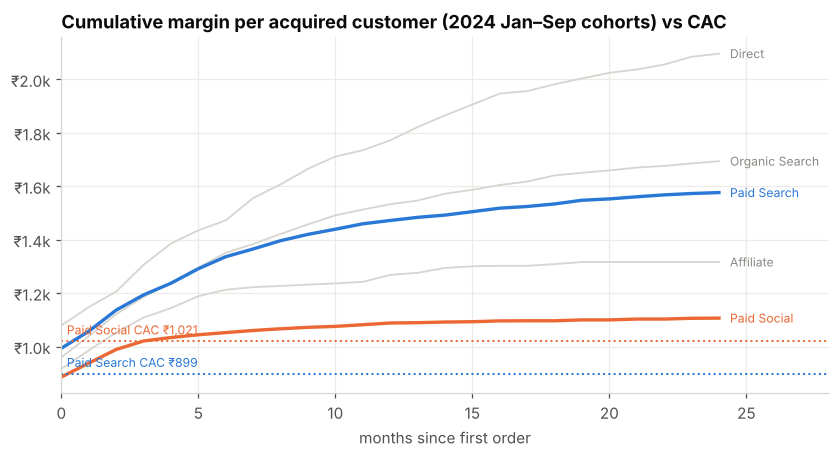

acquisition_channel,Affiliate,Direct,Organic Search,Paid Search,Paid Social
month_offset,,,,,
0,917.0,1079.0,960.0,994.0,886.0
3,1108.0,1306.0,1185.0,1193.0,1021.0
6,1213.0,1472.0,1351.0,1336.0,1052.0
12,1268.0,1772.0,1533.0,1472.0,1088.0
18,1309.0,1982.0,1641.0,1534.0,1097.0
24,1316.0,2096.0,1694.0,1576.0,1107.0


In [6]:
curve = q("""
select acquisition_channel, month_offset,
       sum(sum(gross_margin)) over (partition by acquisition_channel order by month_offset)
         / max(sum(cohort_size)) over (partition by acquisition_channel) as cum_margin
from mart.mart_cohort_retention
where cohort_month between '2024-01-01' and '2024-09-01' and month_offset <= 24
  and acquisition_channel in ('Paid Social', 'Paid Search', 'Organic Search', 'Affiliate', 'Direct')
group by 1, 2 order by 1, 2
""")
cac = ch.set_index("channel").cac
fig, ax = plt.subplots(figsize=(9, 4.2))
ends = []
for c, g in curve.groupby("acquisition_channel"):
    focus = c in ("Paid Social", "Paid Search")
    ax.plot(g.month_offset, g.cum_margin, color=viz.highlight(c), lw=2.2 if focus else 1.2)
    ends.append((c, g.cum_margin.iloc[-1], viz.CHANNEL_COLORS[c] if focus else viz.GREY))
for (c, _, col), y in zip(ends, viz.spread_labels([e[1] for e in ends], 45)):
    ax.text(24.4, y, c, fontsize=8, va="center", color=col)
for c in ("Paid Social", "Paid Search"):
    ax.axhline(cac[c], color=viz.CHANNEL_COLORS[c], ls=":", lw=1.3)
    ax.text(0.2, cac[c] + 25, f"{c} CAC ₹{cac[c]:,.0f}", fontsize=8, color=viz.CHANNEL_COLORS[c])
ax.set_xlim(0, 28); ax.yaxis.set_major_formatter(fmt_inr); ax.set_xlabel("months since first order")
ax.set_title("Cumulative margin per acquired customer (2024 Jan–Sep cohorts) vs CAC")
curve.pivot(index="month_offset", columns="acquisition_channel", values="cum_margin").loc[[0, 3, 6, 12, 18, 24]].round(0)

- **Paid Search pays back on the first order** (first-order margin is above CAC) and then keeps compounding.
- **Paid Social needs 3–4 months to pay back on product margin**, and its curve flattens early. After
  24 months a Paid Social customer has generated about 30% less margin than a Paid Search one (₹1,107 vs ₹1,576).
- Most value arrives in **month 0** for every channel. That is why first-order economics (discounts,
  returns, COD/RTO) matter so much for LTV.

## 4. LTV by cohort and by segment

In [7]:
coh = q("""
select date_trunc('quarter', cohort_month) as cohort_quarter,
       count(*) filter (where eligible_90d)  as n_90,  avg(margin_90d)  filter (where eligible_90d)  as ltv_90d,
       count(*) filter (where eligible_365d) as n_365, avg(margin_365d) filter (where eligible_365d) as ltv_365d
from mart.mart_customer_ltv group by 1 order by 1
""")
coh.round(0)

,cohort_quarter,n_90,ltv_90d,n_365,ltv_365d
0,2024-01-01,1302,1136.0,1302,1454.0
1,2024-04-01,1243,1211.0,1243,1470.0
2,2024-07-01,1512,1038.0,1512,1276.0
3,2024-10-01,1735,1143.0,1735,1419.0
4,2025-01-01,1519,1050.0,1519,1305.0
5,2025-04-01,1630,1221.0,1630,1508.0
6,2025-07-01,2070,1048.0,1390,1198.0
7,2025-10-01,2594,1158.0,0,NaN
8,2026-01-01,2188,1125.0,0,NaN
9,2026-04-01,1423,1210.0,0,NaN


Cohort LTV is stable over time: 90-day margin LTV stays within a narrow band for every quarter. Blended LTV
has not deteriorated despite the mix shift, because within-channel value held up (notebook 03 §4).
Segment differences (sale-acquired, first-order returns, COD) are in notebook 03 §5. The largest is
**sale-acquired customers, worth less than half** the 12-month margin of full-price customers.

## 5. Predictive LTV: BG/NBD-family models + Gamma-Gamma, chosen on a holdout year

**Setup**
- **Calibration:** all valid orders up to 30 Sep 2025, for customers whose first order was by 30 Jun 2025.
- **Holdout:** 1 Oct 2025 – 30 Sep 2026 (12 months). Models never see it.
- Time unit: weeks. *x* = repeat orders, *t_x* = weeks from first to last order, *T* = weeks from first order to the calibration end.
- **Candidates:** BG/NBD and MBG/NBD (which also lets a customer drop out right after the *first* order),
  each fitted either on everyone ("pooled") or separately per acquisition-channel group ("segmented").
  The model is chosen by holdout accuracy, not by in-sample fit.

In [8]:
from clv_models import fit_mbgnbd, mbgnbd_expected_purchases, mbgnbd_p_alive

CAL_END, HOLD_END = "2025-09-30 23:59:59", "2026-09-30 23:59:59"
GROUP = {"Paid Social": "Paid Social", "Paid Search": "Paid Search", "Organic Search": "Organic Search",
         "Direct": "Direct, Email & Referral", "Email": "Direct, Email & Referral", "Referral": "Direct, Email & Referral"}


def rfm_table(orders, end):
    g = orders.sort_values("order_ts").groupby("user_id")
    t = pd.DataFrame({
        "x": g.size() - 1,
        "t_x": (g.order_ts.max() - g.first_order_ts.first()).dt.total_seconds() / (7 * 86400),
        "T": (pd.Timestamp(end) - g.first_order_ts.first()).dt.total_seconds() / (7 * 86400),
        "channel": g.acquisition_channel.first(),
        # monetary value: mean margin of REPEAT orders (Gamma-Gamma convention excludes the first order)
        "m_repeat": g.gross_margin.apply(lambda s: s.iloc[1:].mean() if len(s) > 1 else np.nan),
        "margin_to_date": g.gross_margin.sum(),
    })
    t["group"] = t.channel.map(GROUP).fillna("Affiliate, Organic Social & Unattributed")
    return t


o = q("""
select o.user_id, o.order_ts, o.gross_margin, c.first_order_ts, c.acquisition_channel
from core.fct_orders o join core.dim_customers c using (user_id) where o.is_valid_order
""")
o["order_ts"] = pd.to_datetime(o.order_ts); o["first_order_ts"] = pd.to_datetime(o.first_order_ts)
o_cal = o[o.first_order_ts <= "2025-06-30 23:59:59"]
cal = o_cal[o_cal.order_ts <= CAL_END]
hold = o_cal[(o_cal.order_ts > CAL_END) & (o_cal.order_ts <= HOLD_END)]
rfm = rfm_table(cal, CAL_END)
rfm["hold_orders"] = hold.groupby("user_id").size().reindex(rfm.index, fill_value=0)
rfm["hold_margin"] = hold.groupby("user_id").gross_margin.sum().reindex(rfm.index, fill_value=0)
print(f"customers: {len(rfm):,}; with >=1 repeat in calibration: {(rfm.x > 0).sum():,}")

MODELS = {"BG/NBD": (fit_bgnbd, bgnbd_expected_purchases, bgnbd_p_alive),
          "MBG/NBD": (fit_mbgnbd, mbgnbd_expected_purchases, mbgnbd_p_alive)}
H = 52.18
for name, (fit, pred, _) in MODELS.items():
    params = fit(rfm.x, rfm.t_x, rfm["T"])
    rfm[f"{name} pooled"] = pred(params, H, rfm.x, rfm.t_x, rfm["T"])
    rfm[f"{name} segmented"] = 0.0
    for grp, d in rfm.groupby("group"):
        params = fit(d.x, d.t_x, d["T"])
        rfm.loc[d.index, f"{name} segmented"] = pred(params, H, d.x, d.t_x, d["T"])
cands = ["BG/NBD pooled", "BG/NBD segmented", "MBG/NBD pooled", "MBG/NBD segmented"]
comp = pd.DataFrame({
    "predicted_holdout_orders": [rfm[c].sum() for c in cands],
    "total_error_pct": [(rfm[c].sum() / rfm.hold_orders.sum() - 1) * 100 for c in cands],
    "mean_abs_error_per_customer": [(rfm[c] - rfm.hold_orders).abs().mean() for c in cands],
    "worst_group_error_pct": [(rfm.groupby("group")[c].sum() / rfm.groupby("group").hold_orders.sum() - 1).abs().max() * 100 for c in cands],
}, index=cands)
print(f"actual holdout repeat orders: {rfm.hold_orders.sum():,}")
comp.round(3)

customers: 8,941; with >=1 repeat in calibration: 2,377
actual holdout repeat orders: 1,249


,predicted_holdout_orders,total_error_pct,mean_abs_error_per_customer,worst_group_error_pct
BG/NBD pooled,1849.687,48.093,0.275,247.273
BG/NBD segmented,1840.182,47.332,0.270,66.103
MBG/NBD pooled,1421.516,13.812,0.226,136.751
MBG/NBD segmented,1406.561,12.615,0.222,40.158


In [9]:
best = "MBG/NBD segmented"
by_grp = rfm.groupby("group").agg(customers=("x", "size"), actual=("hold_orders", "sum"),
                                  bg_pooled=("BG/NBD pooled", "sum"), chosen=(best, "sum"))
by_grp["chosen_error_pct"] = (by_grp.chosen / by_grp.actual - 1) * 100
by_grp.round(1)

,customers,actual,bg_pooled,chosen,chosen_error_pct
group,,,,,
"Affiliate, Organic Social & Unattributed",1129,116,221.5,162.6,40.2
"Direct, Email & Referral",1427,358,353.3,417.6,16.7
Organic Search,1921,320,415.3,376.6,17.7
Paid Search,2104,336,446.4,339.4,1.0
Paid Social,2360,119,413.3,110.4,-7.3


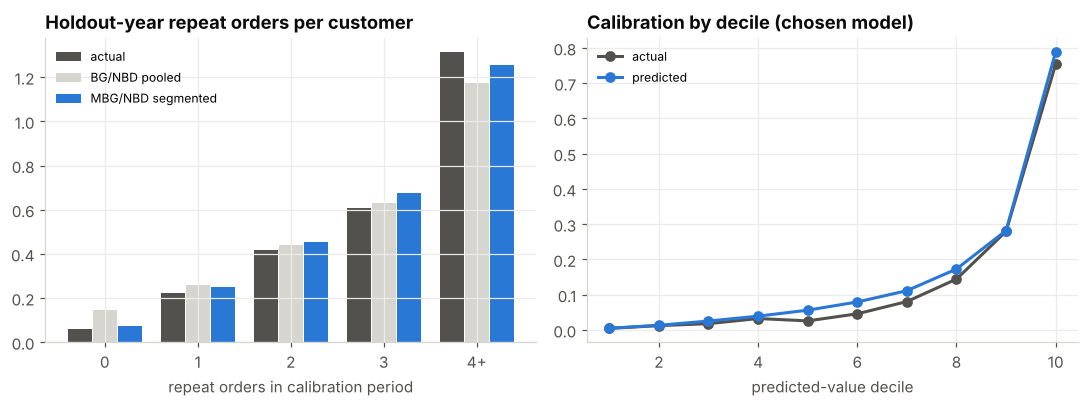

In [10]:
rfm["pred_orders"] = rfm[best]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
by_x = rfm.assign(freq=rfm.x.clip(upper=4).astype(str).replace("4", "4+")).groupby("freq")[["hold_orders", "BG/NBD pooled", "pred_orders"]].mean()
xx = np.arange(len(by_x))
axes[0].bar(xx - 0.27, by_x.hold_orders, 0.26, color=viz.INK_2, label="actual")
axes[0].bar(xx, by_x["BG/NBD pooled"], 0.26, color=viz.GREY_LIGHT, label="BG/NBD pooled")
axes[0].bar(xx + 0.27, by_x.pred_orders, 0.26, color=viz.BLUE, label="MBG/NBD segmented")
axes[0].set_xticks(xx, by_x.index); axes[0].set_xlabel("repeat orders in calibration period")
axes[0].set_title("Holdout-year repeat orders per customer"); axes[0].legend(fontsize=8)
rfm["decile"] = pd.qcut(rfm.pred_orders.rank(method="first"), 10, labels=False) + 1
dec = rfm.groupby("decile")[["hold_orders", "pred_orders"]].mean()
axes[1].plot(dec.index, dec.hold_orders, color=viz.INK_2, marker="o", label="actual")
axes[1].plot(dec.index, dec.pred_orders, color=viz.BLUE, marker="o", label="predicted")
axes[1].set_xlabel("predicted-value decile"); axes[1].set_title("Calibration by decile (chosen model)"); axes[1].legend(fontsize=8)
fig.tight_layout()

**Model choice and validation**
- Plain BG/NBD assumes every one-time buyer is still "alive", so it badly over-predicts for customers with
  no repeat purchase. That is fatal for Paid Social, where most customers buy once.
- **MBG/NBD fitted per channel group** cuts total holdout error from about +48% to about +13%, and predicts the
  critical groups (Paid Social, Paid Search) within about 7%. It is the chosen model.
- The decile chart shows it **ranks** customers well: actual future orders rise steadily with predicted value.
  That is what matters for targeting.
- The remaining over-prediction (largest for the small mixed Affiliate/Organic Social group, ~17% for organic and
  owned channels) comes from misspecification. Real
  inter-purchase gaps are more regular than Poisson, and loyalty builds with each order, which the model's
  constant dropout probability can't capture. **Use model outputs for ranking and relative comparisons, and
  haircut absolute forecasts by ~10–15%.**

In [11]:
rep = rfm[(rfm.x > 0) & (rfm.m_repeat > 0)]
corr = np.corrcoef(rep.x, rep.m_repeat)[0, 1]
print(f"Gamma-Gamma independence check: corr(frequency, avg repeat margin) = {corr:.3f}  (should be ~0)")
gg = fit_gamma_gamma(rep.x, rep.m_repeat)
pop_mean = gg["p"] * gg["v"] / (gg["q"] - 1)
print(f"population mean margin per repeat order: ₹{pop_mean:,.0f}")
rfm["exp_margin_per_order"] = gg_expected_value(gg, rfm.x.where(rfm.m_repeat > 0, 0), rfm.m_repeat.fillna(1).clip(lower=1))
rfm["pred_margin_12m"] = rfm.pred_orders * rfm.exp_margin_per_order
val = rfm.groupby("group").agg(customers=("x", "size"), actual_holdout_margin=("hold_margin", "mean"),
                               predicted_margin=("pred_margin_12m", "mean"))
val.loc["ALL"] = [len(rfm), rfm.hold_margin.mean(), rfm.pred_margin_12m.mean()]
val["error_pct"] = (val.predicted_margin / val.actual_holdout_margin - 1) * 100
val.round(1)

Gamma-Gamma independence check: corr(frequency, avg repeat margin) = -0.048  (should be ~0)
population mean margin per repeat order: ₹1,056


,customers,actual_holdout_margin,predicted_margin,error_pct
group,,,,
"Affiliate, Organic Social & Unattributed",1129.0,93.4,151.9,62.8
"Direct, Email & Referral",1427.0,272.3,303.9,11.6
Organic Search,1921.0,176.9,205.1,16.0
Paid Search,2104.0,165.3,170.7,3.3
Paid Social,2360.0,45.4,48.5,6.7
ALL,8941.0,144.2,164.7,14.3


Gamma-Gamma's key assumption (order value independent of purchase frequency) holds: the correlation is near zero.
The combined model reproduces the **ranking** of channel groups on next-year margin, with Paid Social customers
expected to generate the least.

### Scoring current customers (refit on all data up to the snapshot)

In [12]:
cur = rfm_table(o, HOLD_END)
cur["p_alive"] = 0.0
cur["expected_orders_12m"] = 0.0
for grp, d in cur.groupby("group"):
    params = fit_mbgnbd(d.x, d.t_x, d["T"])
    cur.loc[d.index, "p_alive"] = mbgnbd_p_alive(params, d.x, d.t_x, d["T"])
    cur.loc[d.index, "expected_orders_12m"] = mbgnbd_expected_purchases(params, H, d.x, d.t_x, d["T"])
rep2 = cur[(cur.x > 0) & (cur.m_repeat > 0)]
gg2 = fit_gamma_gamma(rep2.x, rep2.m_repeat)
cur["expected_margin_per_order"] = gg_expected_value(gg2, cur.x.where(cur.m_repeat > 0, 0), cur.m_repeat.fillna(1).clip(lower=1))
cur["predicted_margin_next_12m"] = cur.expected_orders_12m * cur.expected_margin_per_order
cur["value_segment"] = pd.cut(cur.predicted_margin_next_12m.rank(pct=True), [0, .5, .8, .95, 1.0],
                              labels=["Low", "Medium", "High", "VIP"])
out = cur.reset_index().rename(columns={"channel": "acquisition_channel", "x": "repeat_orders",
                                        "t_x": "recency_weeks", "T": "age_weeks"})
out = out[["user_id", "acquisition_channel", "repeat_orders", "recency_weeks", "age_weeks", "margin_to_date", "p_alive",
           "expected_orders_12m", "expected_margin_per_order", "predicted_margin_next_12m", "value_segment"]]
Path("data/processed").mkdir(parents=True, exist_ok=True)
out.round(4).to_csv("data/processed/customer_clv_predictions.csv", index=False)
db.execute("""CREATE OR REPLACE TABLE mart.mart_customer_clv_predictions AS
              SELECT * FROM read_csv_auto('data/processed/customer_clv_predictions.csv')""")
summary = out.groupby("acquisition_channel").agg(customers=("user_id", "size"), avg_p_alive=("p_alive", "mean"),
                                                 predicted_margin_next_12m=("predicted_margin_next_12m", "mean"))
summary.sort_values("predicted_margin_next_12m", ascending=False).round(2)

,customers,avg_p_alive,predicted_margin_next_12m
acquisition_channel,,,
Direct,2266,0.15,287.46
Email,343,0.14,281.17
Referral,456,0.11,212.13
Organic Search,4447,0.12,197.54
Paid Search,4504,0.10,172.68
Unattributed,638,0.08,124.50
Affiliate,1222,0.07,116.99
Organic Social,580,0.07,111.81
Paid Social,5848,0.04,66.02


In [13]:
seg = out.groupby("value_segment", observed=True).agg(customers=("user_id", "size"),
        avg_predicted_margin=("predicted_margin_next_12m", "mean"),
        share_of_predicted_margin=("predicted_margin_next_12m", "sum"))
seg["share_of_predicted_margin"] /= seg.share_of_predicted_margin.sum()
seg.round(3)

,customers,avg_predicted_margin,share_of_predicted_margin
value_segment,,,
Low,10152,13.135,0.042
Medium,6091,118.293,0.227
High,3045,406.796,0.390
VIP,1016,1064.531,0.341


Scores are saved to `mart.mart_customer_clv_predictions` (and CSV) for the dashboard and for CRM use. Examples:
- **VIP / High** (top 20% of predicted value): protect them with early access and service recovery. Don't give
  them discounts they don't need.
- **High historical value but low p_alive**: the win-back list. These customers were valuable and are going quiet.
- **Low**: suppress from expensive retargeting audiences.

## 6. CAC, payback and what we can afford to pay

### 6a. The marginal Paid Social customer

In [14]:
run_sql_file(A / "08_paid_social_scale_up.sql")

,period,spend,new_customers,cpc,average_cac,marginal_cac,ltv_margin_90d,repeat_rate_90d,cod_share
0,A: before ramp (Mar24-Feb25),1369730.0,1441,11.40,951.0,NaN,972.0,0.096,0.379
1,B: after ramp (Jun25-May26),3035780.0,2774,15.16,1094.0,1250.0,1027.0,0.106,0.403


Meta spend rose about 2.2× and CPC rose about 33% as the audience saturated. **Average** CAC rose from ₹951 to
₹1,094, but the **marginal** CAC of the extra customers is **₹1,250**. That is above the ~₹1,070 that a Paid
Social customer generates in 12-month product margin. The extra customers were *as good as* earlier ones (90-day
LTV is similar), but they **cost more than they are worth within a year**. The last ~₹16 lakh of annual Meta spend
is the first candidate to cut or reallocate.

### 6b. Contribution-margin sensitivity (ASSUMPTIONS, not data)
Fulfilment costs are not in the dataset. To show how fragile thin LTV:CAC ratios are, the table below applies
**illustrative** per-order costs typical of Indian D2C apparel. They are labelled assumptions, chosen for
illustration, and must be replaced with the real 3PL invoice and payment-gateway rates before any decision.

| Cost (assumed) | Value |
|---|---|
| Forward shipping + packaging per delivered order | ₹80 |
| Payment gateway fee on prepaid orders | 2% of order value |
| COD handling fee per COD order | ₹30 |
| RTO cost per undelivered order (forward + reverse shipping) | ₹160 |
| Reverse pickup per returned order | ₹80 |

In [15]:
cm = q("""
with o as (
  select c.acquisition_channel, o.user_id, o.order_ts, c.first_order_ts, o.is_valid_order, o.is_rto, o.has_return,
         o.payment_type, o.gross_revenue_placed, o.gross_margin,
         date_diff('day', c.first_order_ts, o.order_ts) as day_n
  from core.fct_orders o join core.dim_customers c using (user_id)
  where c.is_customer and c.first_order_ts + interval 395 day <= timestamp '2026-09-30 23:59:59'
    and o.order_ts >= c.first_order_ts - interval 1 day
)
select acquisition_channel as channel, count(distinct user_id) as customers,
       sum(gross_margin) filter (where day_n < 365) / count(distinct user_id) as product_margin_365d,
       sum(case when day_n < 365 then
             gross_margin
             - case when is_valid_order then 80 else 0 end
             - case when is_valid_order and payment_type = 'Prepaid' then 0.02 * gross_revenue_placed else 0 end
             - case when payment_type = 'COD' and (is_valid_order or is_rto) then 30 else 0 end
             - case when is_rto then 160 else 0 end
             - case when has_return then 80 else 0 end
           else 0 end) / count(distinct user_id) as contribution_margin_365d
from o group by 1
""").set_index("channel")
cm = cm.join(ch.set_index("channel")[["cac"]])
cm["ltv_cac_product"] = cm.product_margin_365d / cm.cac
cm["ltv_cac_contribution"] = cm.contribution_margin_365d / cm.cac
cm.sort_values("customers", ascending=False).round(2)

,customers,product_margin_365d,contribution_margin_365d,cac,ltv_cac_product,ltv_cac_contribution
channel,,,,,,
Paid Social,2775,1069.16,898.05,1021.0,1.05,0.88
Paid Search,2415,1472.09,1256.00,899.0,1.64,1.40
Organic Search,2219,1506.29,1288.76,NaN,NaN,NaN
Direct,1167,1620.31,1384.15,NaN,NaN,NaN
Affiliate,674,1335.70,1139.24,246.0,5.43,4.63
Organic Social,318,1349.18,1157.47,NaN,NaN,NaN
Unattributed,308,1327.07,1134.72,NaN,NaN,NaN
Referral,263,1496.50,1275.62,NaN,NaN,NaN
Email,192,1697.74,1455.06,NaN,NaN,NaN


Under these illustrative costs, **Paid Social customers do not recover their acquisition cost within 12 months**
(contribution LTV:CAC below 1). Paid Search remains positive but thin. Their high COD share and the associated
RTO and handling costs hit Paid Social hardest.

### 6c. What CAC data would be needed to go further
1. **Costs for unpaid channels**: SEO agency and content production (Organic Search), influencer and creator
   fees (Organic Social), brand spend (Direct is partly brand-driven).
2. **Campaign-level spend with UTM-matched IDs**, to compute CAC per campaign (prospecting vs retargeting) instead of per platform.
3. **Incrementality tests** (geo holdouts or Meta conversion-lift studies): last-click/first-touch attribution
   credits channels with customers who might have bought anyway. That is the biggest risk for Affiliate and
   retargeting.
4. **Fulfilment cost actuals** (3PL invoices, gateway fees), to replace the §6b assumptions.

### Maximum affordable CAC
With target LTV:CAC = 3× on 12-month product margin: Paid Social ≈ ₹356, Paid Search ≈ ₹491 (`max_cac_at_3x`
in §2). Current CACs are **about 1.8–2.9× those levels**. Either (a) accept a longer payback horizon (state it explicitly,
e.g. 24-month LTV), or (b) lower CAC: cut the marginal Meta spend, shift budget to Paid Search and Affiliate
where they can absorb it, and grow owned channels (Email capture, SEO).